
 Linear SVM
Accuracy: 0.81
Training Time: 8.38 seconds
              precision    recall  f1-score   support

           0       0.74      0.81      0.78       100
           1       0.96      0.95      0.95       100
           2       0.63      0.69      0.66       100
           3       0.88      0.82      0.85       100
           4       0.69      0.68      0.68       100
           5       0.93      0.91      0.92       100
           6       0.54      0.47      0.50       100
           7       0.91      0.86      0.88       100
           8       0.95      0.97      0.96       100
           9       0.86      0.94      0.90       100

    accuracy                           0.81      1000
   macro avg       0.81      0.81      0.81      1000
weighted avg       0.81      0.81      0.81      1000


 Polynomial SVM
Accuracy: 0.802
Training Time: 16.16 seconds
              precision    recall  f1-score   support

           0       0.76      0.81      0.78       100
           1  

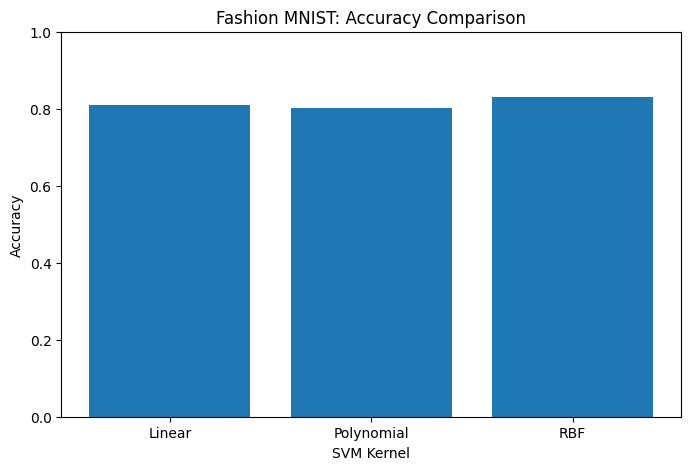

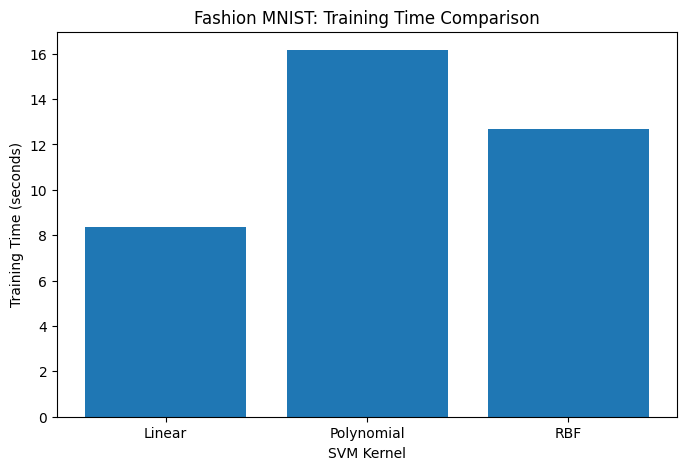


KERNEL ANALYSIS
1. Linear Kernel:
   Advantages: Simple, faster, and uses less computation.
   Disadvantages: Cannot model complex nonlinear boundaries effectively.

2. Polynomial Kernel:
   Advantages: Captures feature interactions and nonlinear patterns.
   Disadvantages: Can be slower and sensitive to polynomial degree.

3. RBF Kernel:
   Advantages: Models complex nonlinear relationships and is flexible.
   Disadvantages: Can require more computation and careful parameter tuning.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Load Fashion MNIST dataset
data = fetch_openml("Fashion-MNIST", version=1, as_frame=False, parser="auto")
X = data.data.astype("float32") / 255.0
y = data.target.astype("int64")

# Use a smaller subset to reduce training time
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=5000, test_size=1000, random_state=42, stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define SVM kernels
models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial": SVC(kernel="poly", degree=3, C=1.0),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}

results = []

# Train and evaluate each model
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Kernel": name,
        "Accuracy": accuracy,
        "Training Time (seconds)": train_time
    })

    print("\n", name, "SVM")
    print("Accuracy:", round(accuracy, 4))
    print("Training Time:", round(train_time, 2), "seconds")
    print(classification_report(y_test, y_pred, zero_division=0))

# Compare performance
results_df = pd.DataFrame(results)
print("\nSVM Kernel Comparison:")
print(results_df.to_string(index=False))

# Plot accuracy comparison
plt.figure(figsize=(8, 5))
plt.bar(results_df["Kernel"], results_df["Accuracy"])
plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy")
plt.title("Fashion MNIST: Accuracy Comparison")
plt.ylim(0, 1)
plt.show()

# Plot training time comparison
plt.figure(figsize=(8, 5))
plt.bar(results_df["Kernel"], results_df["Training Time (seconds)"])
plt.xlabel("SVM Kernel")
plt.ylabel("Training Time (seconds)")
plt.title("Fashion MNIST: Training Time Comparison")
plt.show()

# Advantages and disadvantages
print("\nKERNEL ANALYSIS")
print("1. Linear Kernel:")
print("   Advantages: Simple, faster, and uses less computation.")
print("   Disadvantages: Cannot model complex nonlinear boundaries effectively.")

print("\n2. Polynomial Kernel:")
print("   Advantages: Captures feature interactions and nonlinear patterns.")
print("   Disadvantages: Can be slower and sensitive to polynomial degree.")

print("\n3. RBF Kernel:")
print("   Advantages: Models complex nonlinear relationships and is flexible.")
print("   Disadvantages: Can require more computation and careful parameter tuning.")